In [1]:
import re
import sys
import numpy as np
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display
from credit_default_risk.config import INTERIM_DIR  , TARGET_COL , TRAIN_FILE
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split



In [2]:
df = pd.read_parquet(INTERIM_DIR / TRAIN_FILE)


### Dataset Overview

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")


Rows: 246,008
Columns: 118


Data types and missingness dist

In [18]:
missing = df.isna().sum()

column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": missing,
    "missing_pct": (missing / len(df) * 100).round(2),
}).sort_values("missing_pct", ascending=False)

display(column_summary)

,dtype,missing,missing_pct
CREDIT_CARD_AVG_UTILIZATION,float64,177029,71.96
CREDIT_CARD_AVG_BALANCE,float64,176325,71.67
COMMONAREA_MEDI,float64,171811,69.84
COMMONAREA_MODE,float64,171811,69.84
COMMONAREA_AVG,float64,171811,69.84
NONLIVINGAPARTMENTS_AVG,float64,170729,69.40
NONLIVINGAPARTMENTS_MODE,float64,170729,69.40
NONLIVINGAPARTMENTS_MEDI,float64,170729,69.40
FONDKAPREMONT_MODE,str,168215,68.38
LIVINGAPARTMENTS_AVG,float64,168119,68.34


Duplicate IDs and target balance

In [4]:
print("Duplicate SK_ID_CURR values:", df["SK_ID_CURR"].duplicated().sum())

target_counts = df[TARGET_COL].value_counts(dropna=False).sort_index()
target_summary = pd.DataFrame({
    "count": target_counts,
    "percent": (target_counts / len(df) * 100).round(2),
})

display(target_summary)

class_counts = df[TARGET_COL].value_counts()
print(f"Majority-to-minority ratio: {class_counts.max() / class_counts.min():.2f}:1")

Duplicate SK_ID_CURR values: 0


,count,percent
TARGET,,
0,226148,91.93
1,19860,8.07


Majority-to-minority ratio: 11.39:1


### Model Based Feature Importance (Features to to start with)

#### Functions

In [7]:
def get_feature_importance (applications: pd.DataFrame, TOP_K_FEATURES = 40):
    
    def prepare_categorical_values(frame, cat_columns):
        """Replace missing categorical values with a string CatBoost can encode."""
        frame = frame.copy()

        for col in cat_columns:
            frame[col] = (
                frame[col]
                .astype("string")
                .fillna("__MISSING__")
                .astype(str)
            )

        return frame
    
    target_col = "TARGET"
    id_col = "SK_ID_CURR"

    labeled = applications.loc[applications[target_col].notna()].copy()
    y = pd.to_numeric(labeled[target_col], errors="raise")

    if not set(y.unique()).issubset({0, 1}):
        raise ValueError(f"{target_col} must contain only 0/1 labels.")

    y = y.astype("int8")

    print(f"Labeled rows: {len(labeled):,}")
    print("Target distribution:")
    print(y.value_counts(normalize=True).sort_index().rename("proportion"))


    # Exclude the target and identifier from the model features.
    drop_cols = [col for col in [target_col, id_col] if col in labeled.columns]
    X = labeled.drop(columns=drop_cols)

    # Split labeled rows into 70% train, 15% validation, and 15% test.
    X_train, X_holdout, y_train, y_holdout = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42,
        stratify=y,
    )

    X_valid, X_test, y_valid, y_test = train_test_split(
        X_holdout,
        y_holdout,
        test_size=0.50,
        random_state=42,
        stratify=y_holdout,
    )

    # Pass categorical columns to CatBoost by name.
    cat_features = X.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns.tolist()

    X_train = prepare_categorical_values(X_train, cat_features)
    X_valid = prepare_categorical_values(X_valid, cat_features)
    X_test = prepare_categorical_values(X_test, cat_features)


    model = CatBoostClassifier(
        iterations=1500,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=100,
        allow_writing_files=False,
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=(X_valid, y_valid),
        early_stopping_rounds=100,
        use_best_model=True,
    )

    # Evaluate the held-out test set.
    test_probabilities = model.predict_proba(X_test)[:, 1]

    print(f"Best iteration: {model.get_best_iteration()}")
    print(f"Test ROC AUC: {roc_auc_score(y_test, test_probabilities):.4f}")
    print(f"Test Average Precision: {average_precision_score(y_test, test_probabilities):.4f}")


    # Plot the 25 most important features.
    importance = pd.Series(
        model.feature_importances_,
        index=X_train.columns,
    ).nlargest(TOP_K_FEATURES).sort_values()

    ax = importance.plot(kind="barh", figsize=(9, 8))
    ax.set_title("CatBoost: top 25 feature importances")
    ax.set_xlabel("Feature importance")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()
    return importance
    

#### Feature importance using CatBoostClassifier

Labeled rows: 246,008
Target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64
0:	test: 0.5751280	best: 0.5751280 (0)	total: 141ms	remaining: 3m 31s
100:	test: 0.7562413	best: 0.7562413 (100)	total: 6.49s	remaining: 1m 29s
200:	test: 0.7629328	best: 0.7629328 (200)	total: 12.9s	remaining: 1m 23s
300:	test: 0.7664306	best: 0.7664306 (300)	total: 19.6s	remaining: 1m 18s
400:	test: 0.7688863	best: 0.7689169 (396)	total: 26s	remaining: 1m 11s
500:	test: 0.7702874	best: 0.7702874 (500)	total: 32.6s	remaining: 1m 5s
600:	test: 0.7708600	best: 0.7708854 (598)	total: 39.7s	remaining: 59.4s
700:	test: 0.7712001	best: 0.7712001 (700)	total: 46.5s	remaining: 53.1s
800:	test: 0.7714959	best: 0.7715321 (798)	total: 53.2s	remaining: 46.5s
900:	test: 0.7715959	best: 0.7716763 (871)	total: 1m	remaining: 39.9s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7716763448
bestIteration = 871

Shrink model to first 872 iterations.
Best iteration: 871
Test

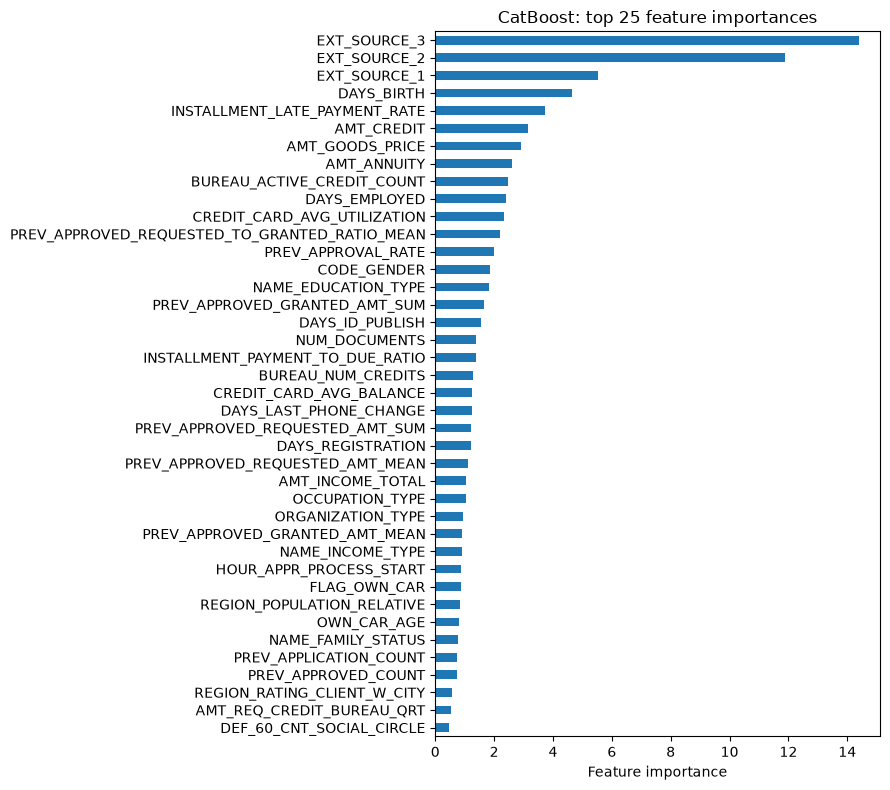

In [8]:
top_features = get_feature_importance(df)

In [9]:
top_features

DEF_60_CNT_SOCIAL_CIRCLE                          0.481596
AMT_REQ_CREDIT_BUREAU_QRT                         0.529466
REGION_RATING_CLIENT_W_CITY                       0.560882
PREV_APPROVED_COUNT                               0.722610
PREV_APPLICATION_COUNT                            0.736889
NAME_FAMILY_STATUS                                0.755485
OWN_CAR_AGE                                       0.799204
REGION_POPULATION_RELATIVE                        0.840249
FLAG_OWN_CAR                                      0.860677
HOUR_APPR_PROCESS_START                           0.865229
NAME_INCOME_TYPE                                  0.900910
PREV_APPROVED_GRANTED_AMT_MEAN                    0.923060
ORGANIZATION_TYPE                                 0.926788
OCCUPATION_TYPE                                   1.027858
AMT_INCOME_TOTAL                                  1.057506
PREV_APPROVED_REQUESTED_AMT_MEAN                  1.107599
DAYS_REGISTRATION                                 1.2282

## Numerical Features Analysis: 

In [10]:

def get_feature_types(frame):
    features = frame.drop(columns=[TARGET_COL, "SK_ID_CURR"], errors="ignore")

    categorical = features.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns.tolist()

    numeric_candidates = features.select_dtypes(include="number").columns.tolist()

    binary_numeric = [
        col for col in numeric_candidates
        if col.startswith("FLAG_") or features[col].dropna().nunique() <= 2
    ]

    categorical = list(dict.fromkeys(categorical + binary_numeric))
    numerical = [col for col in numeric_candidates if col not in categorical]

    return numerical, categorical


numerical_features, categorical_features = get_feature_types(df)
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(categorical_features)

Numerical features: 88
Categorical features: 28
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EMERGENCYSTATE_MODE']


#### Age

In [12]:
eda_df = df.copy()

print("Positive DAYS_EMPLOYED values:")
display(
    eda_df.loc[eda_df["DAYS_EMPLOYED"] > 0, "DAYS_EMPLOYED"]
    .value_counts()
    .head()
)

eda_df["AGE_YEARS"] = (
    -eda_df["DAYS_BIRTH"].where(eda_df["DAYS_BIRTH"] < 0) / 365.25
)

eda_df["EMPLOYMENT_YEARS"] = (
    -eda_df["DAYS_EMPLOYED"].where(eda_df["DAYS_EMPLOYED"] <= 0) / 365.25
)

eda_df["AGE_BIN"] = pd.cut(
    eda_df["AGE_YEARS"],
    bins=[18, 25, 35, 45, 55, 65, np.inf],
    labels=["18–24", "25–34", "35–44", "45–54", "55–64", "65+"],
    right=False,
).cat.add_categories(["Missing"]).fillna("Missing")

eda_df["EMPLOYMENT_BIN"] = pd.cut(
    eda_df["EMPLOYMENT_YEARS"],
    bins=[0, 1, 3, 5, 10, 20, np.inf],
    labels=["<1", "1–2", "3–4", "5–9", "10–19", "20+"],
    right=False,
).cat.add_categories(["Missing"]).fillna("Missing")

Positive DAYS_EMPLOYED values:


DAYS_EMPLOYED
365243    44143
Name: count, dtype: int64

AGE_BIN


,applications,default_rate,default_rate_pct
AGE_BIN,,,
18–24,9841,0.124378,12.44
25–34,58061,0.106922,10.69
35–44,67372,0.084397,8.44
45–54,56151,0.069741,6.97
55–64,48357,0.053705,5.37
65+,6226,0.036781,3.68


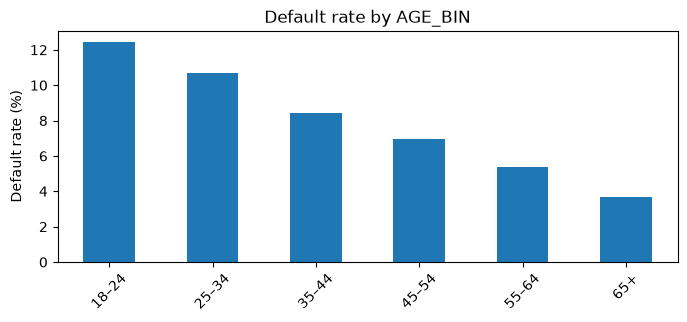

EMPLOYMENT_BIN


,applications,default_rate,default_rate_pct
EMPLOYMENT_BIN,,,
<1,22393,0.109945,10.99
1–2,49260,0.110617,11.06
3–4,37558,0.096225,9.62
5–9,51877,0.074330,7.43
10–19,30719,0.055243,5.52
20+,10058,0.040962,4.10
Missing,44143,0.053689,5.37


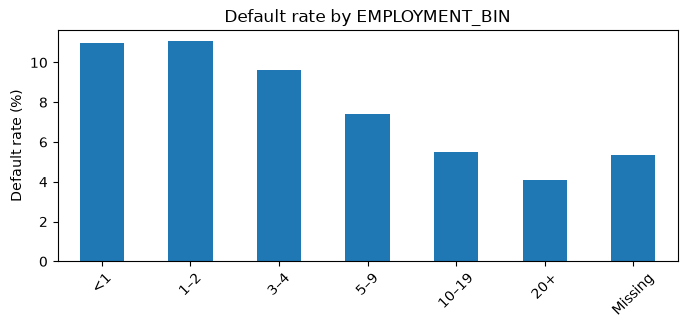

In [19]:
for col in ["AGE_BIN", "EMPLOYMENT_BIN"]:
    summary = (
        eda_df.groupby(col, observed=True)[TARGET_COL]
        .agg(["size", "mean"])
        .rename(columns={"size": "applications", "mean": "default_rate"})
    )
    summary["default_rate_pct"] = (summary["default_rate"] * 100).round(2)

    print(col)
    display(summary)

    summary["default_rate_pct"].plot.bar(
        figsize=(8, 3),
        title=f"Default rate by {col}",
        ylabel="Default rate (%)",
        xlabel="",
    )
    plt.xticks(rotation=45)
    plt.show()

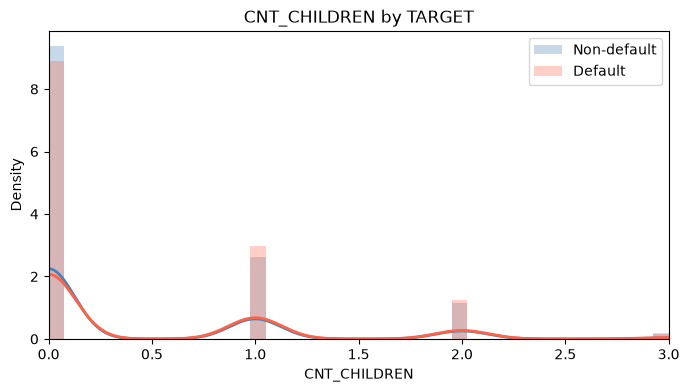

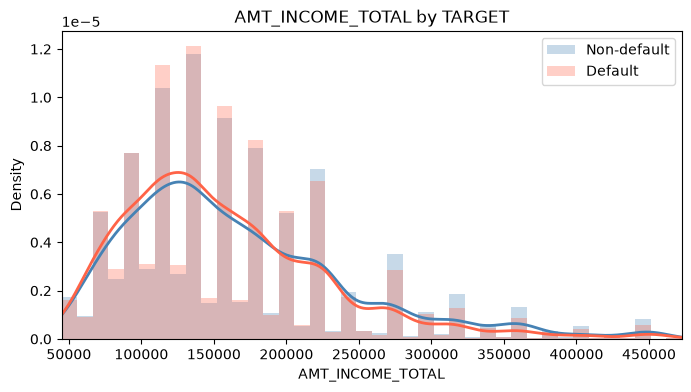

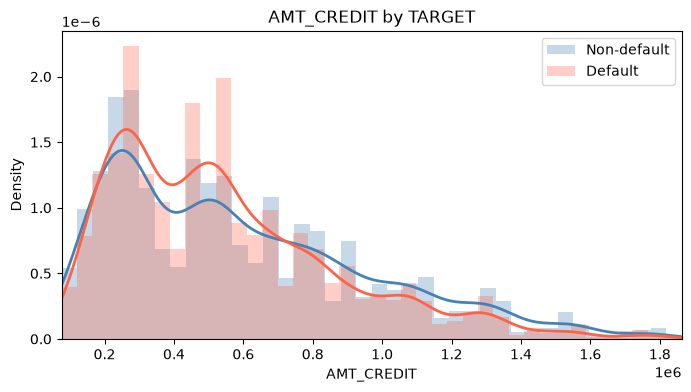

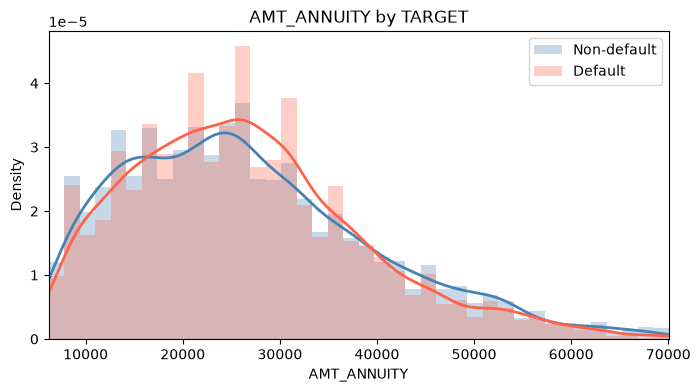

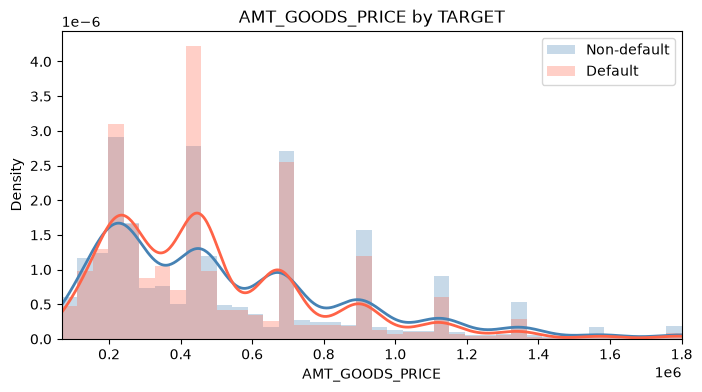

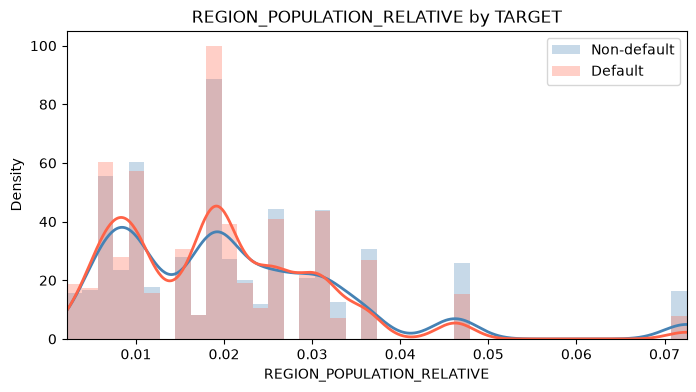

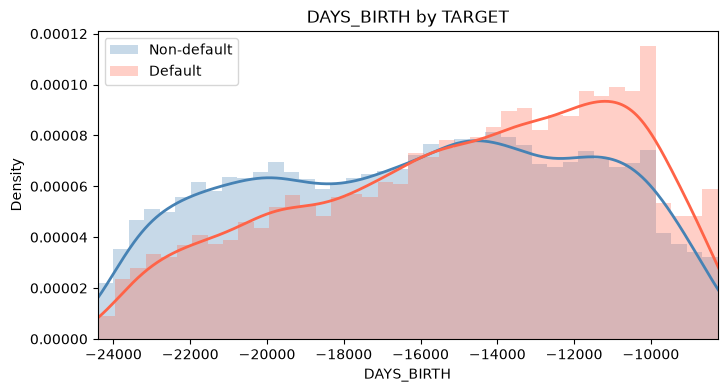

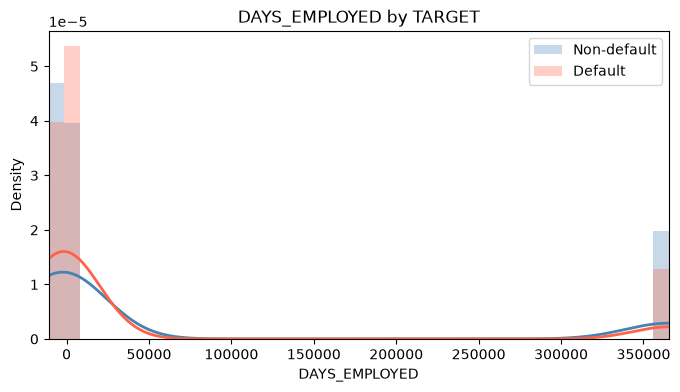

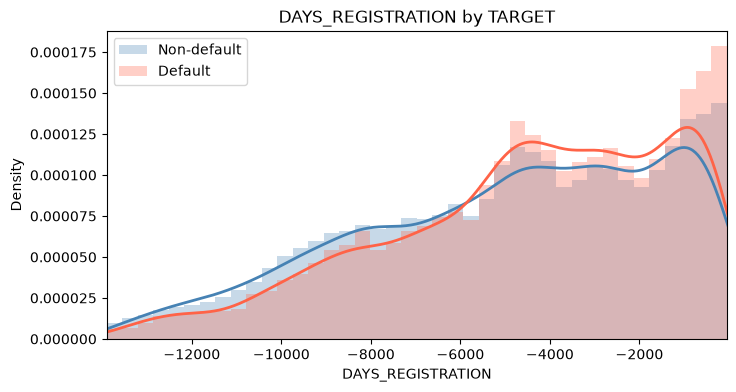

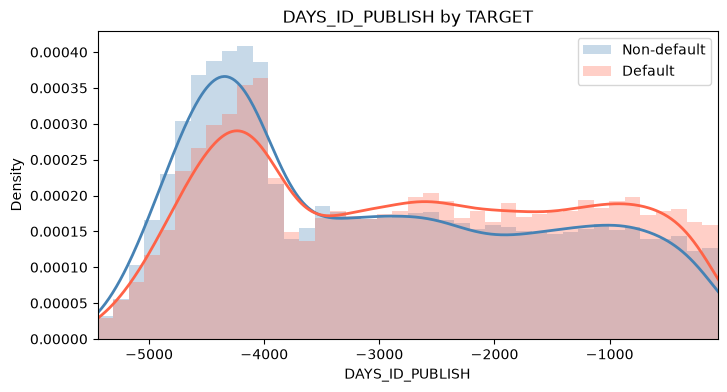

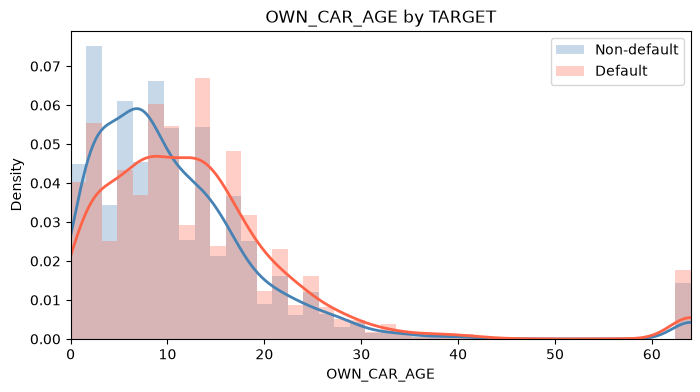

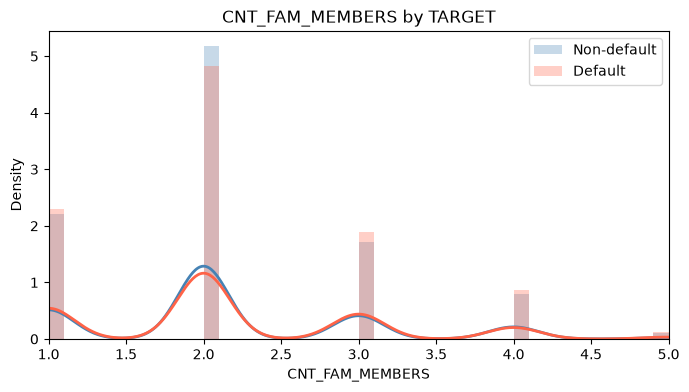

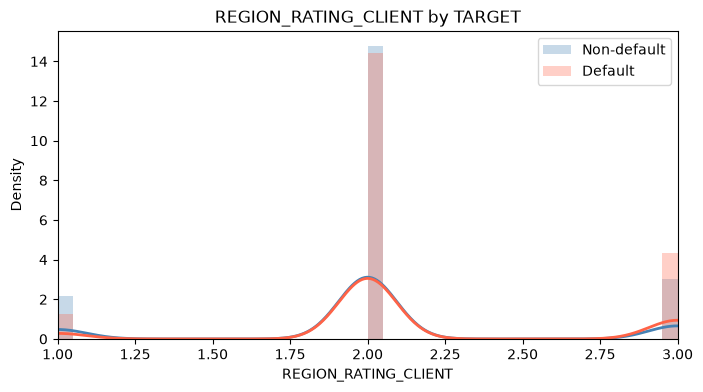

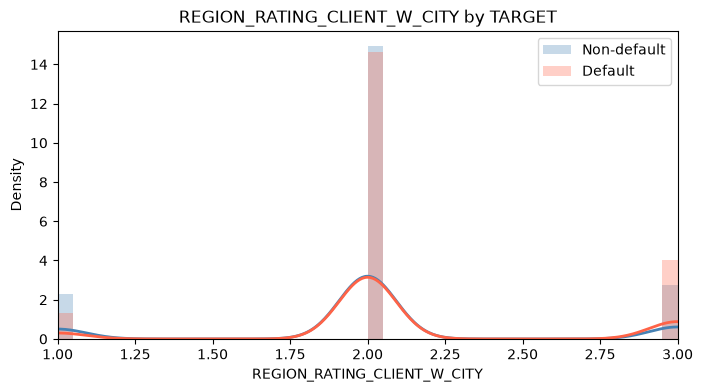

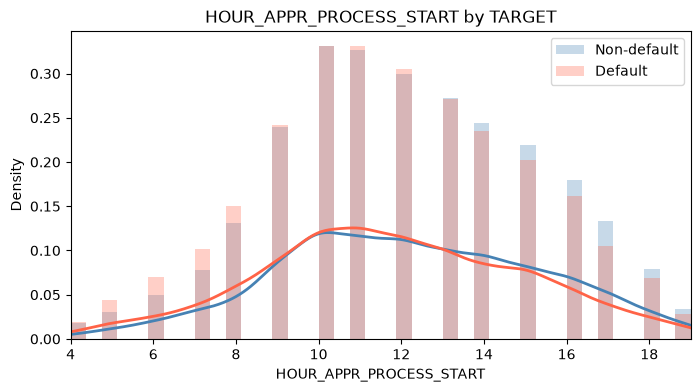

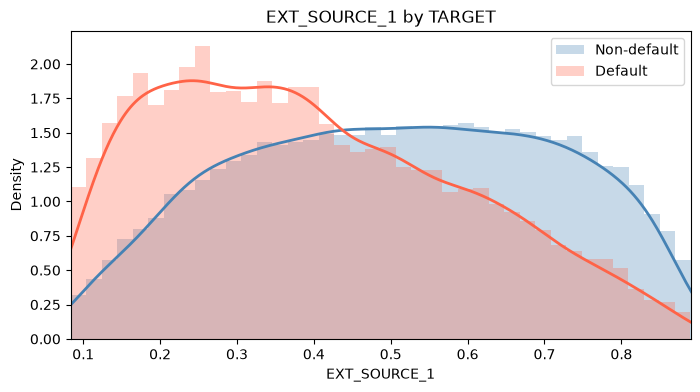

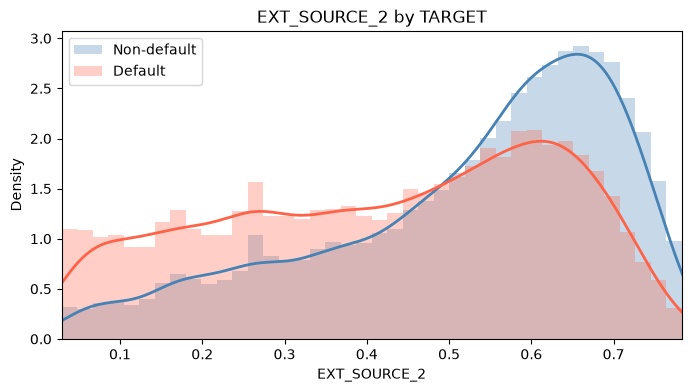

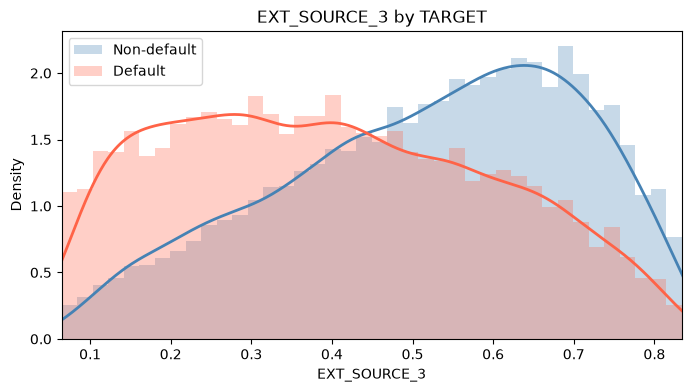

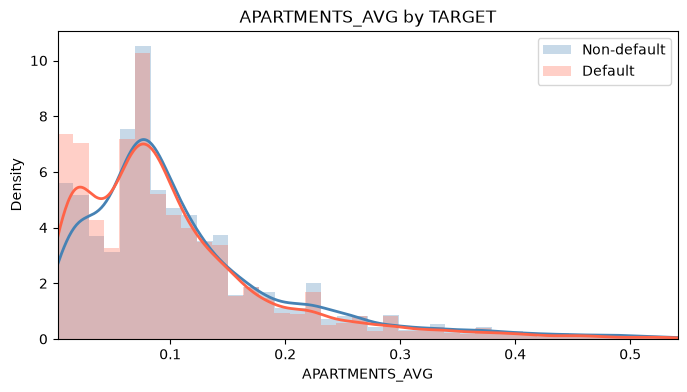

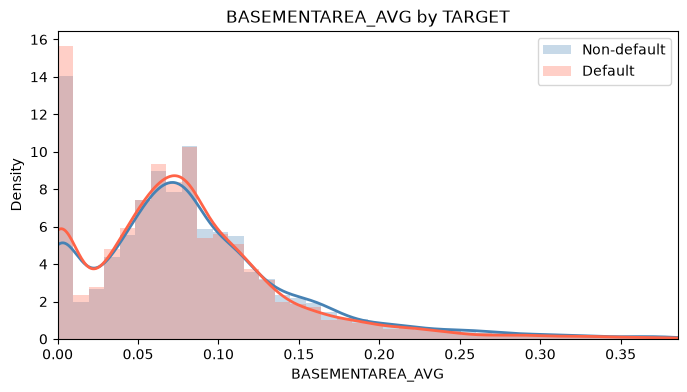

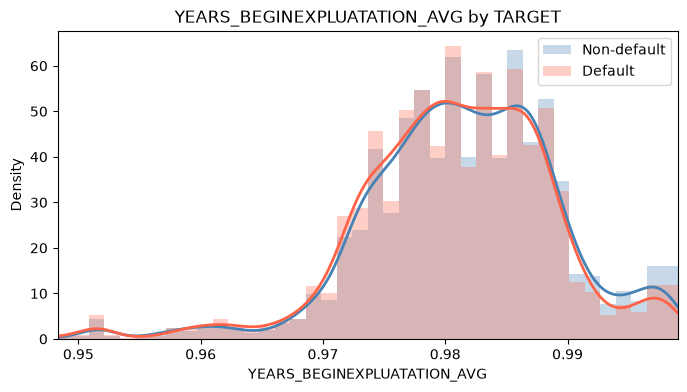

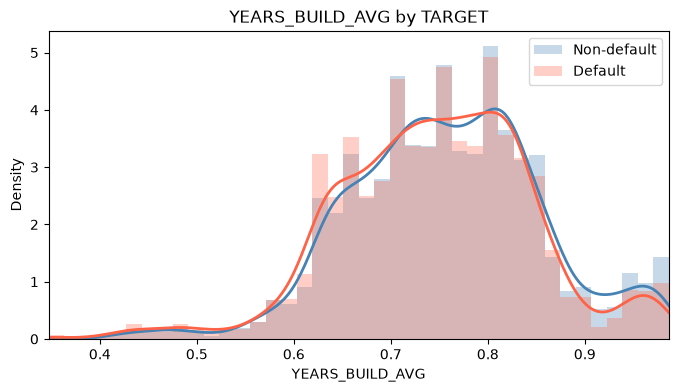

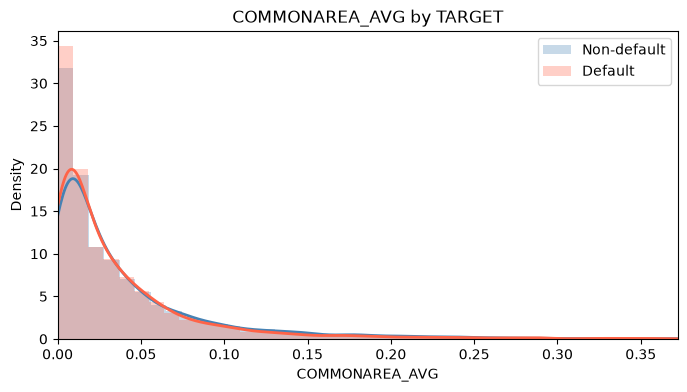

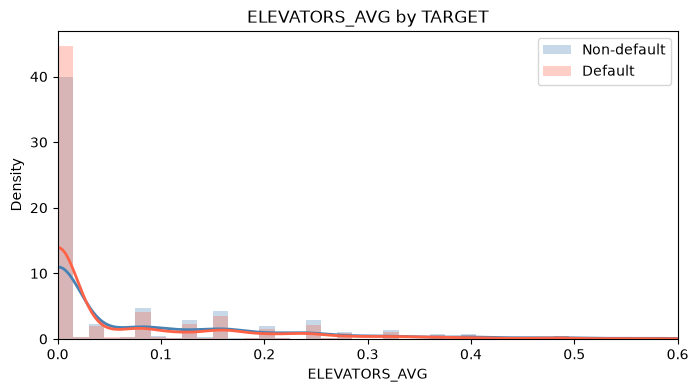

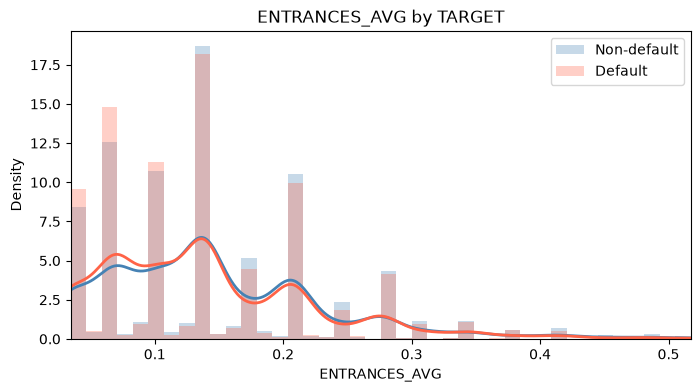

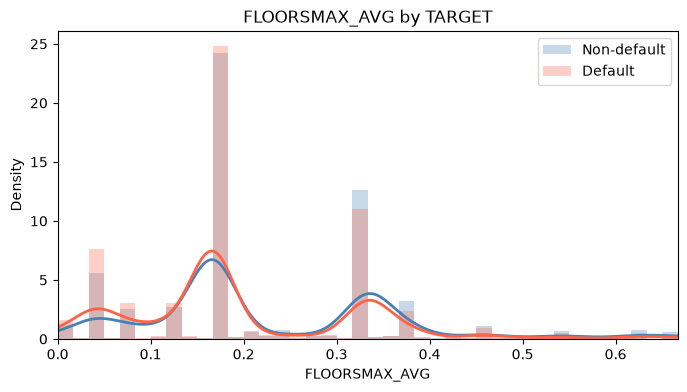

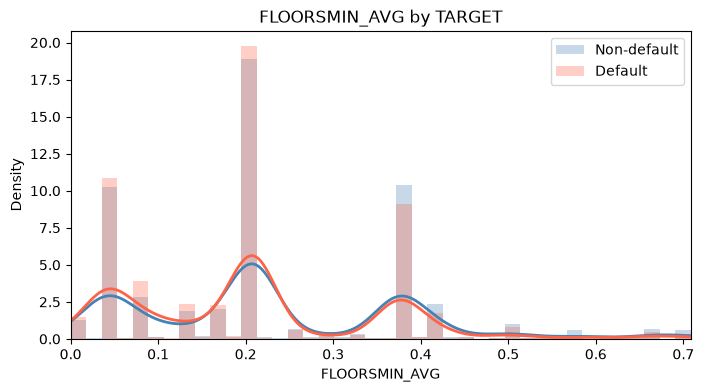

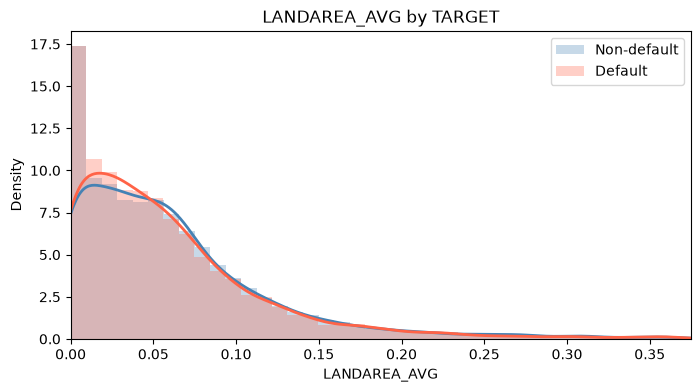

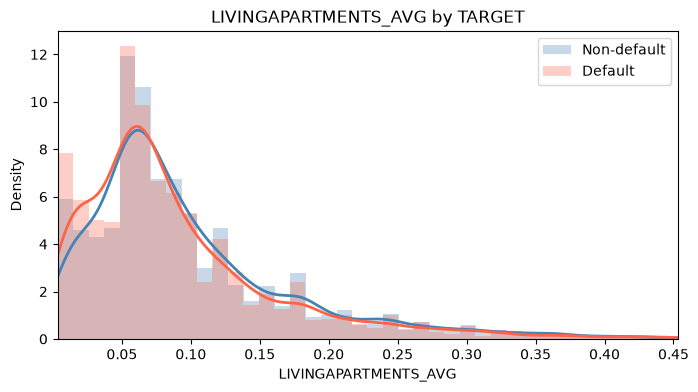

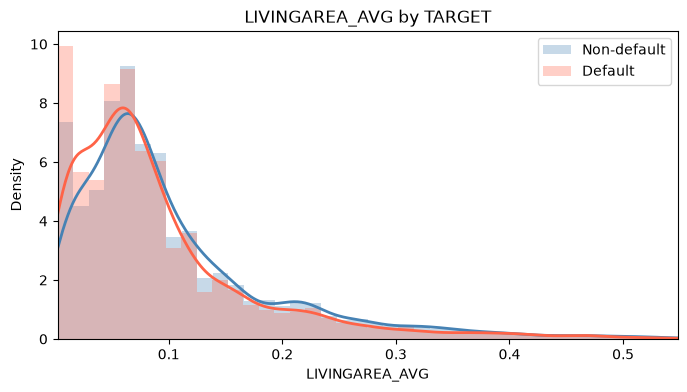

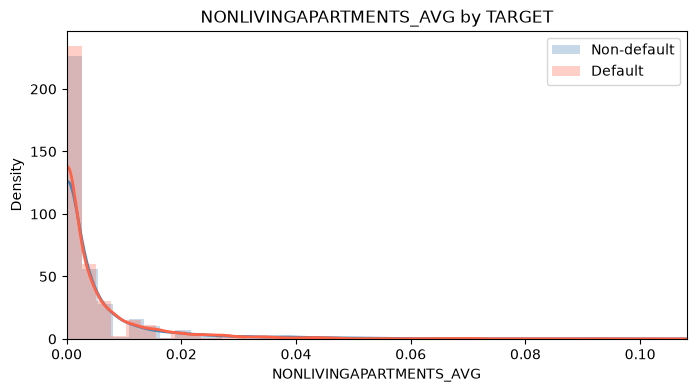

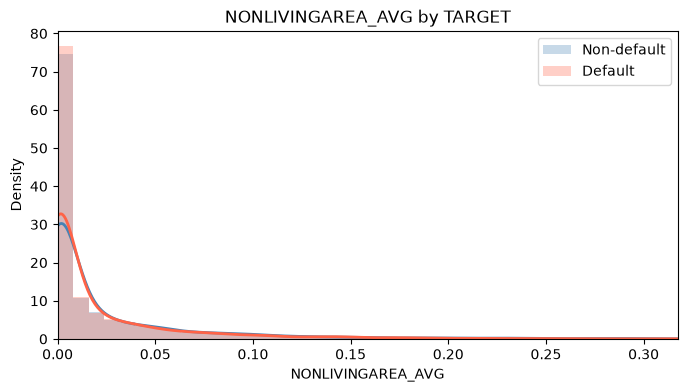

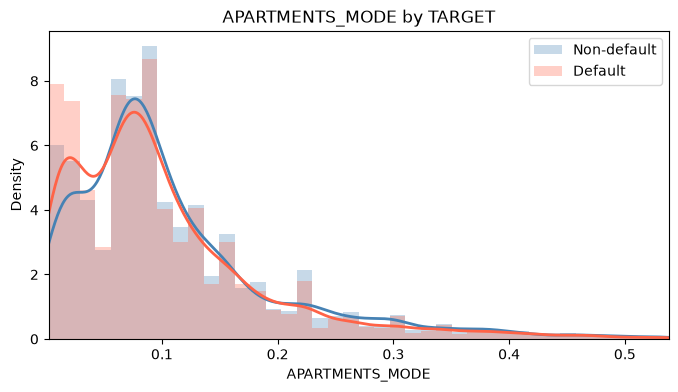

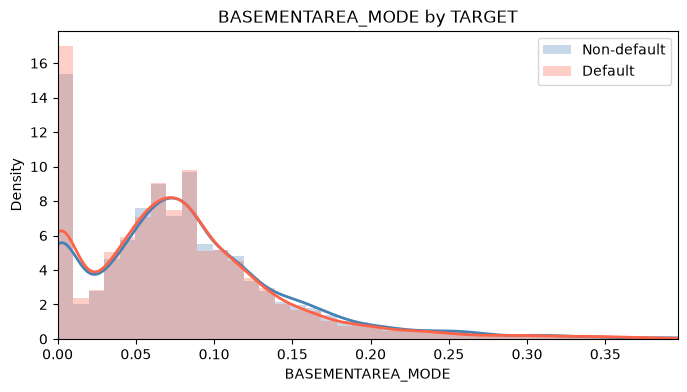

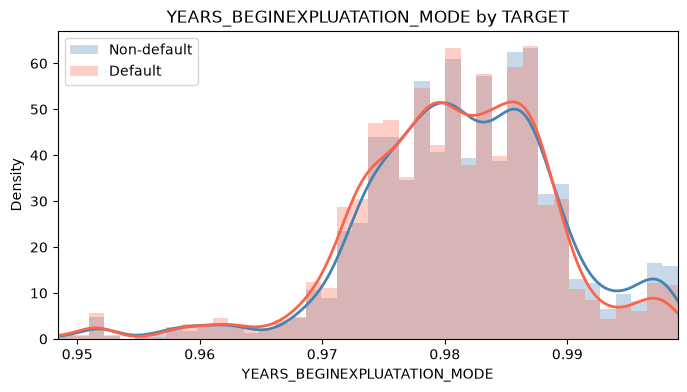

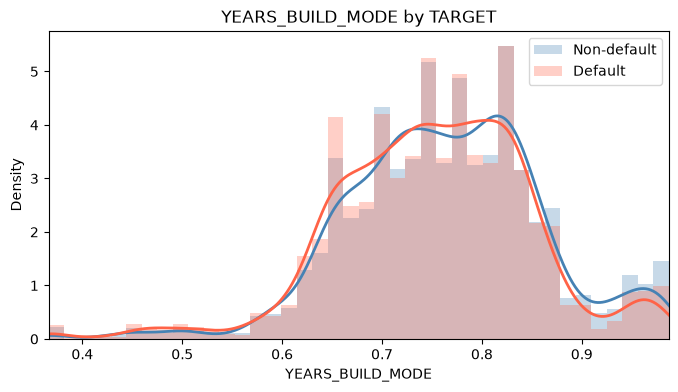

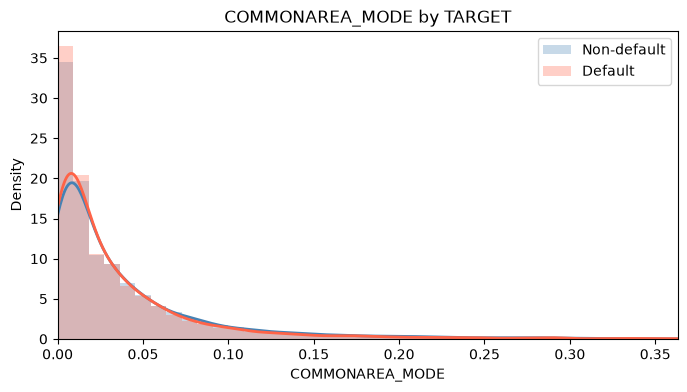

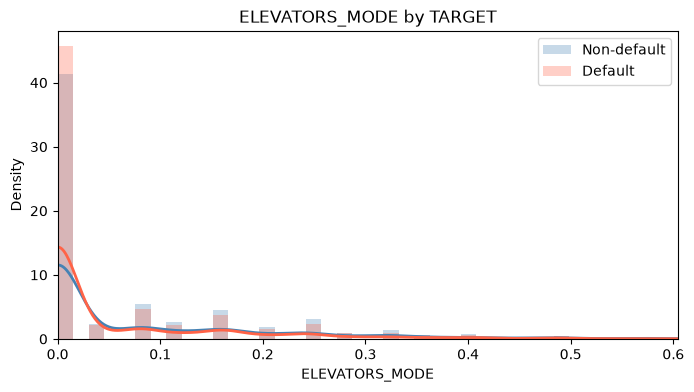

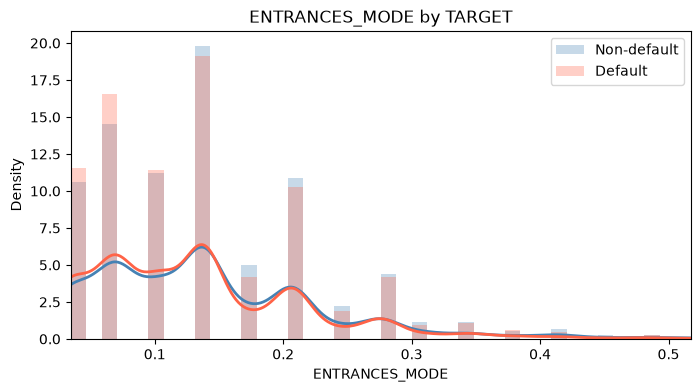

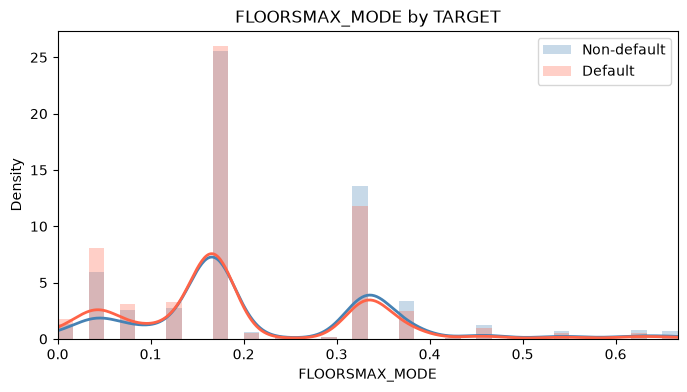

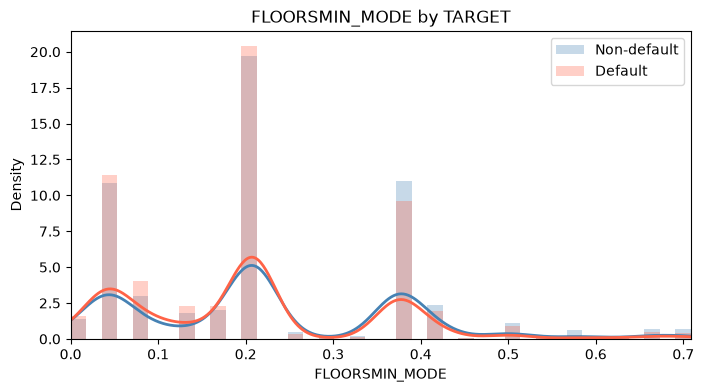

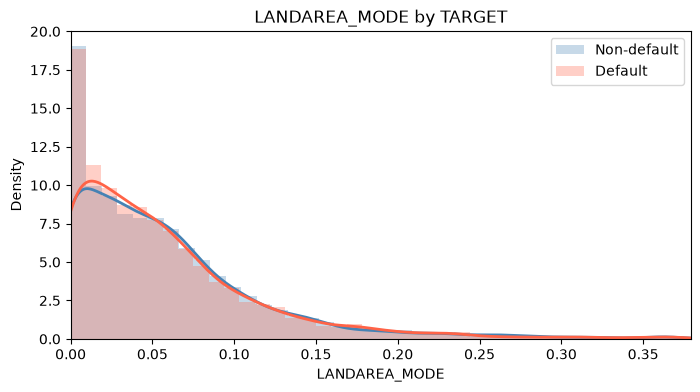

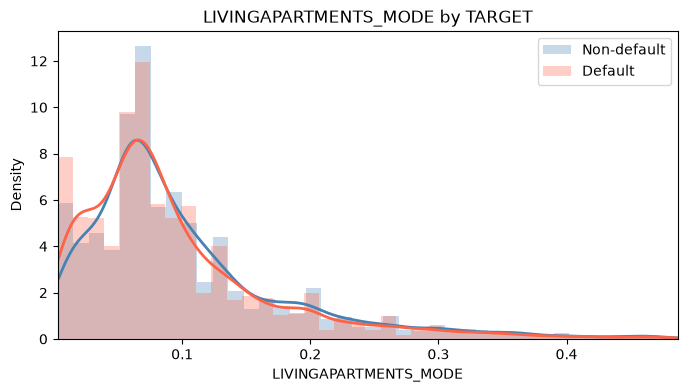

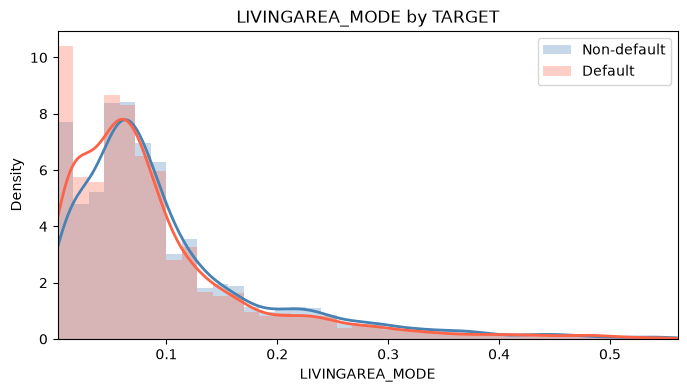

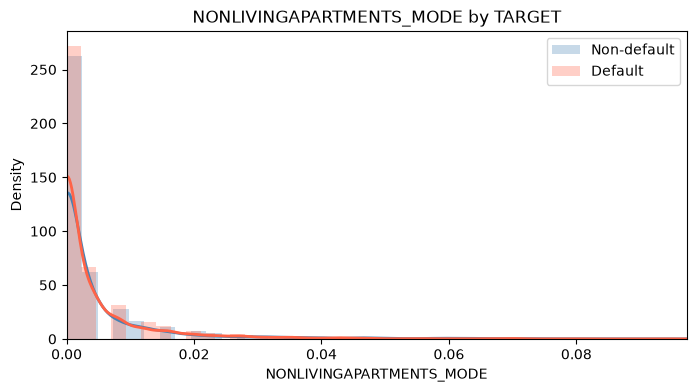

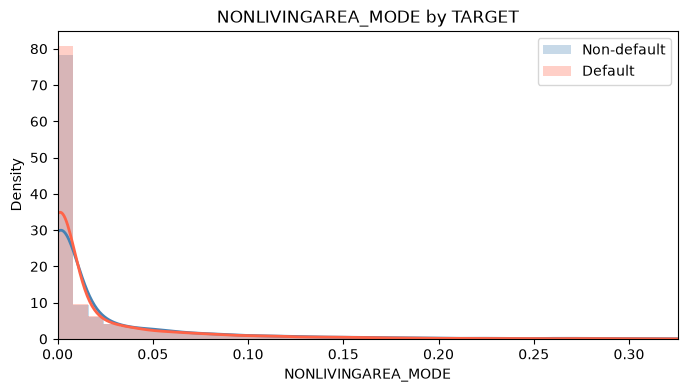

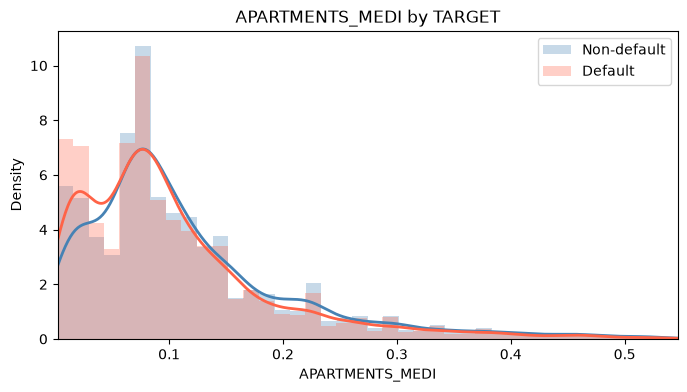

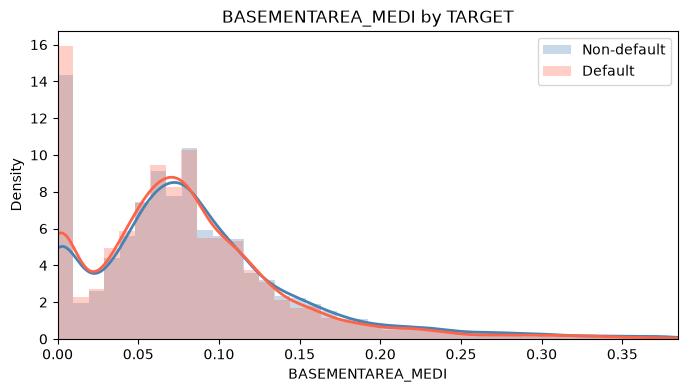

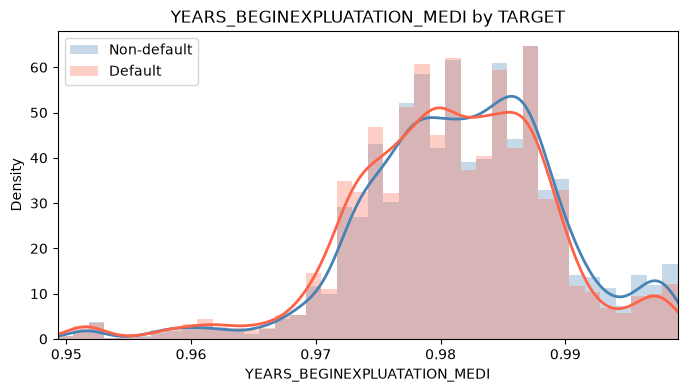

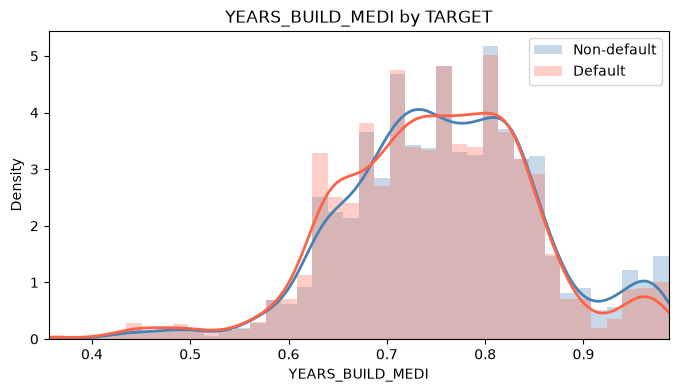

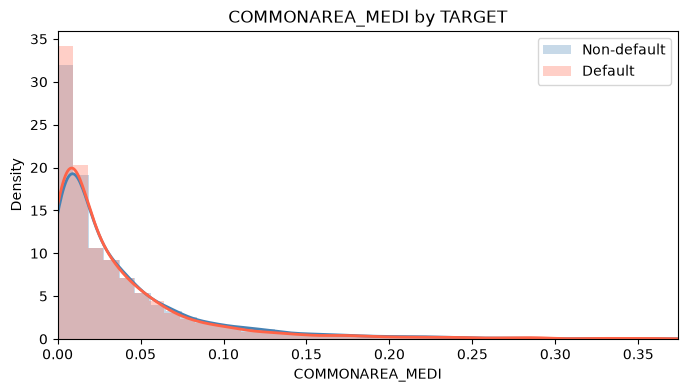

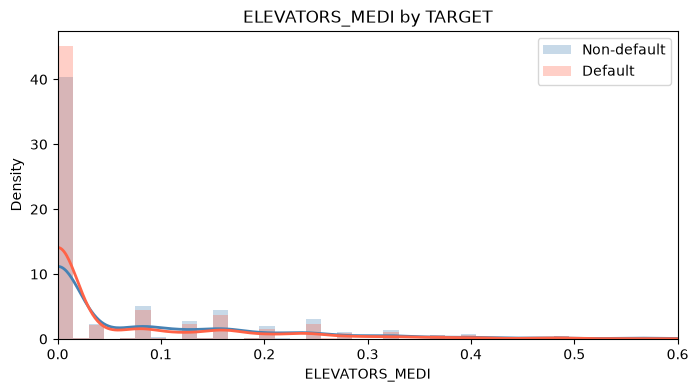

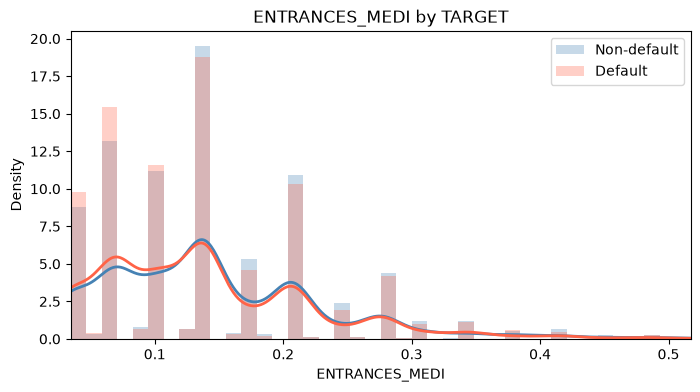

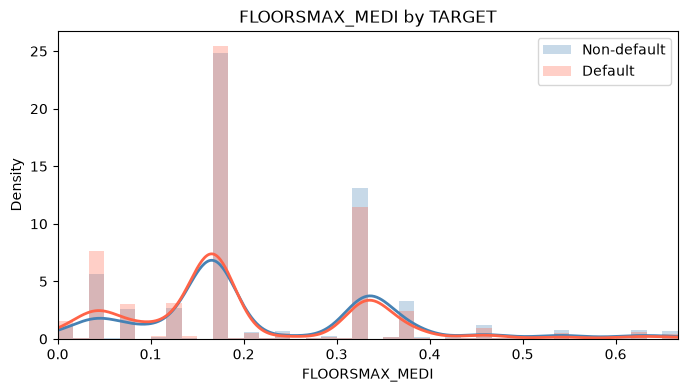

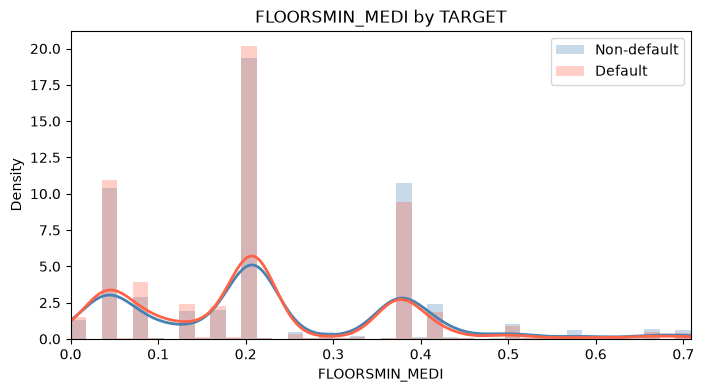

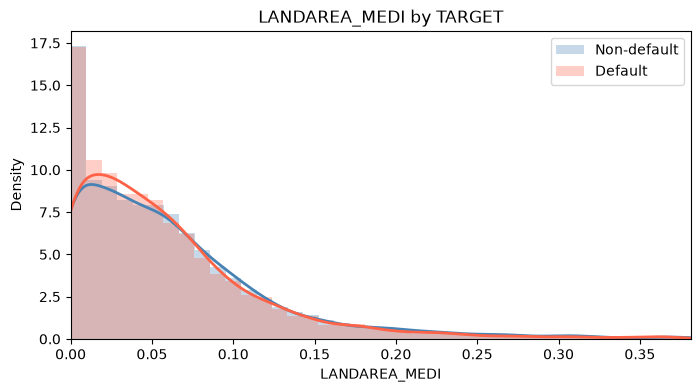

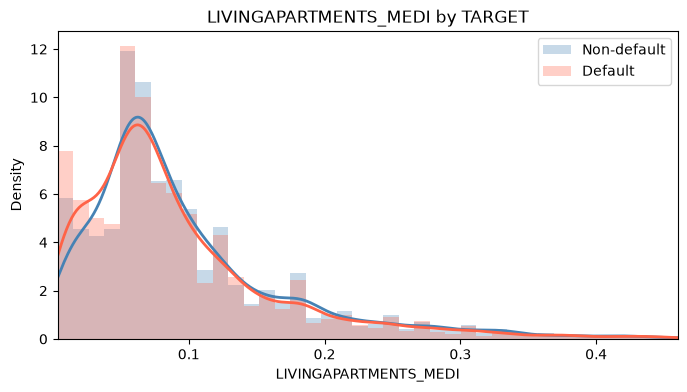

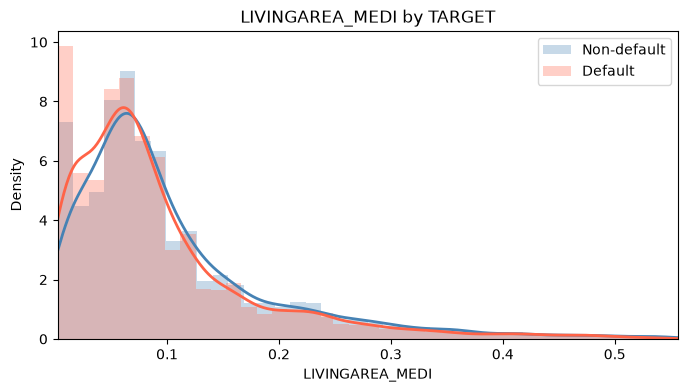

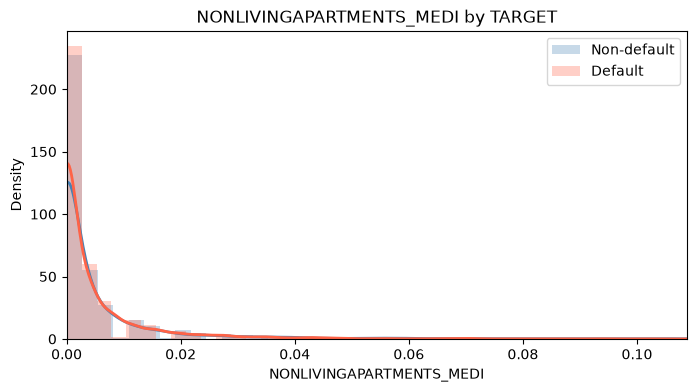

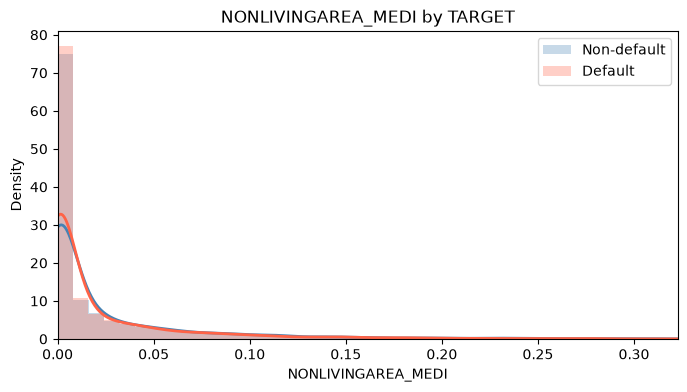

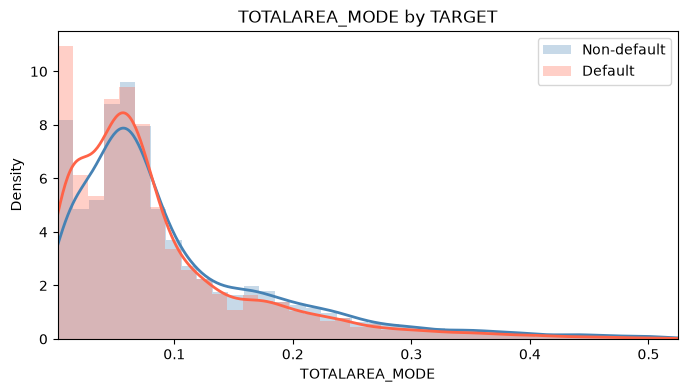

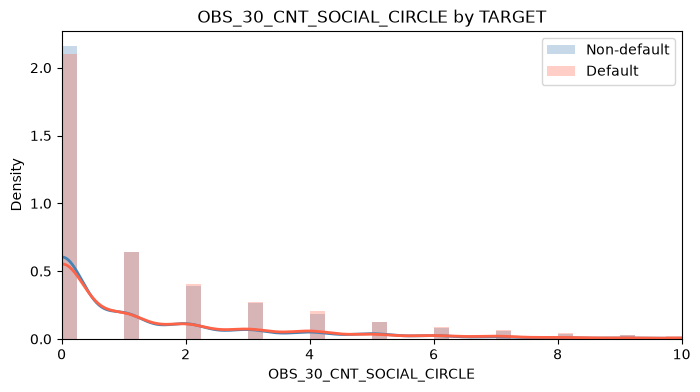

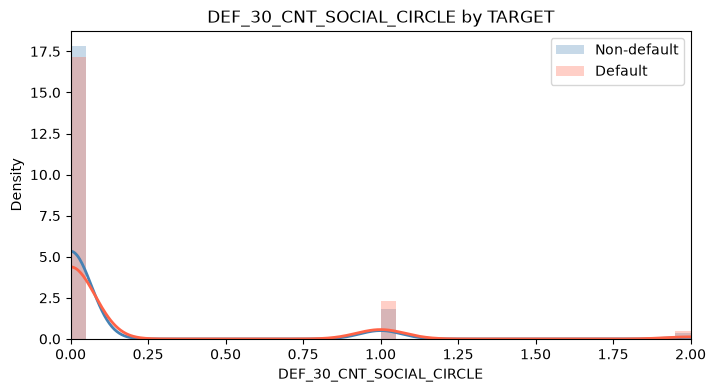

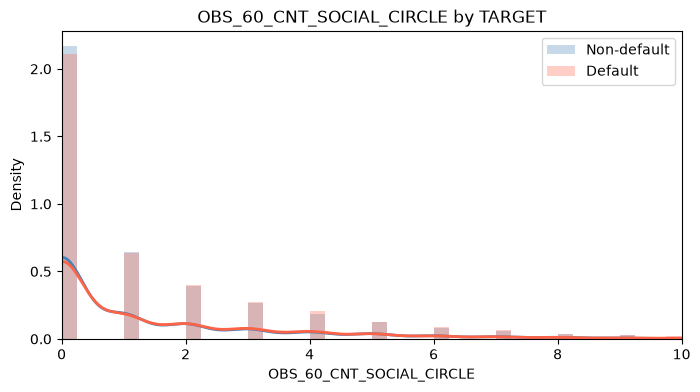

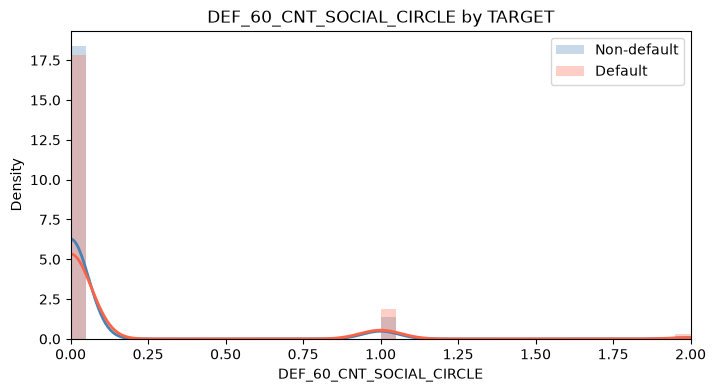

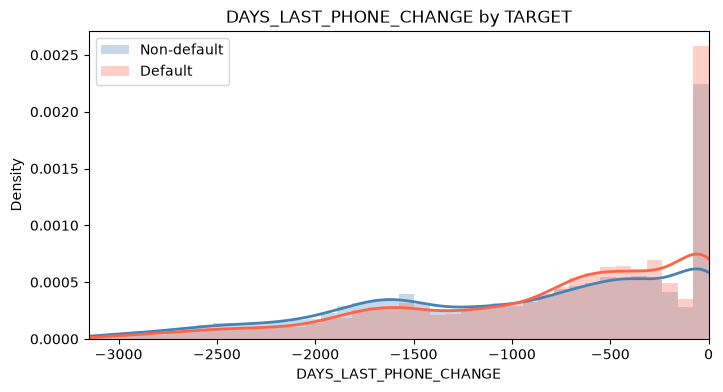

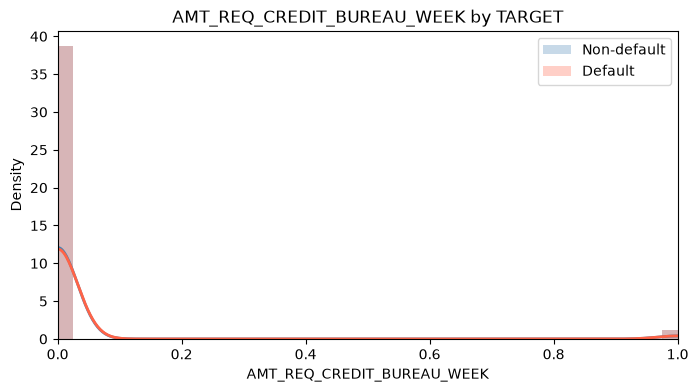

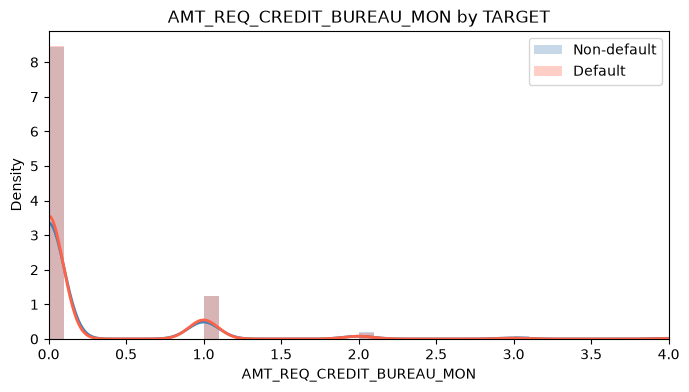

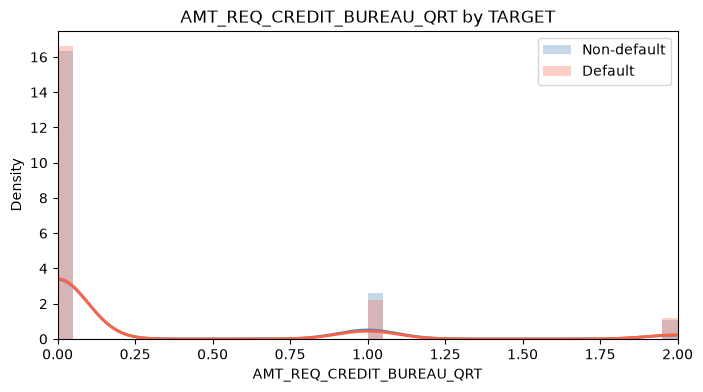

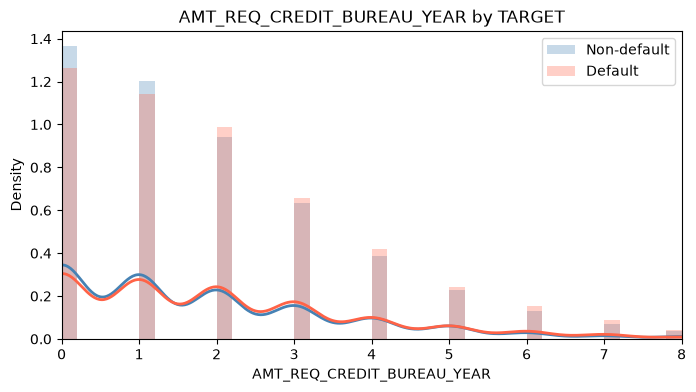

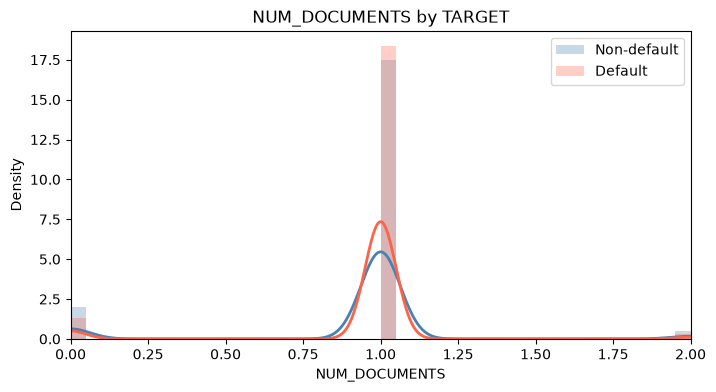

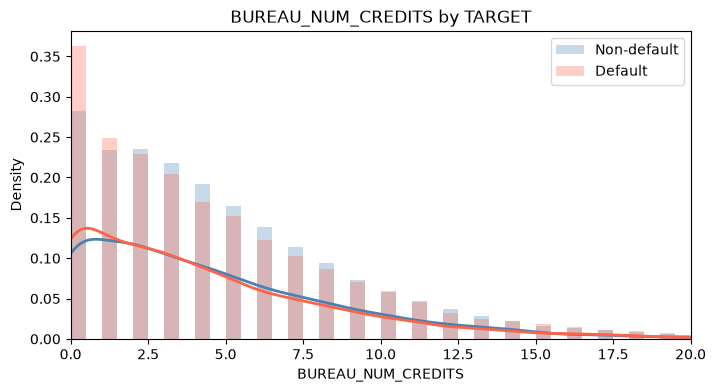

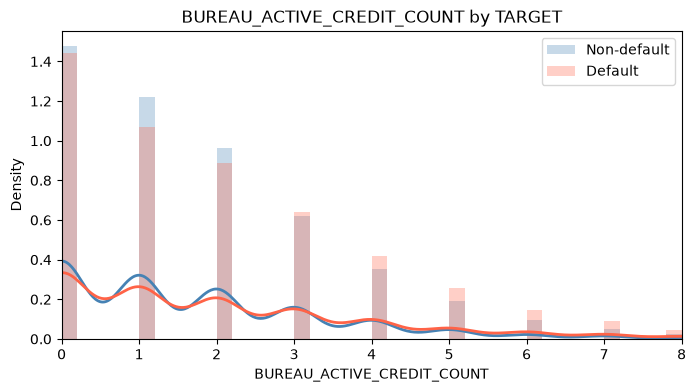

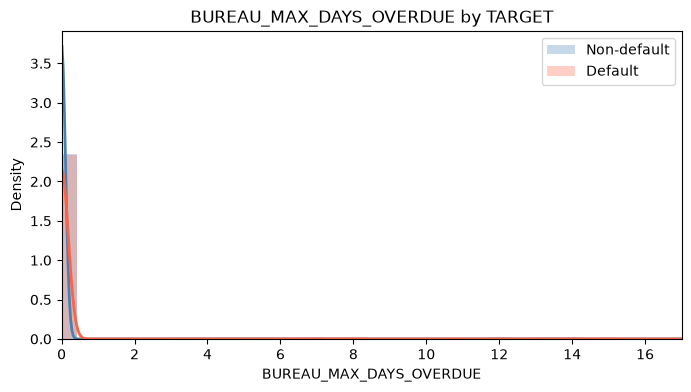

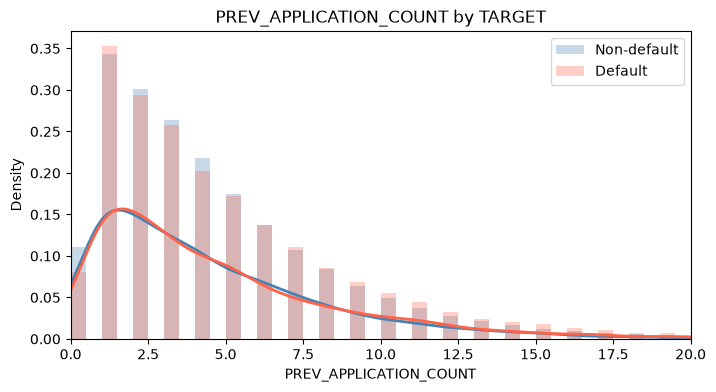

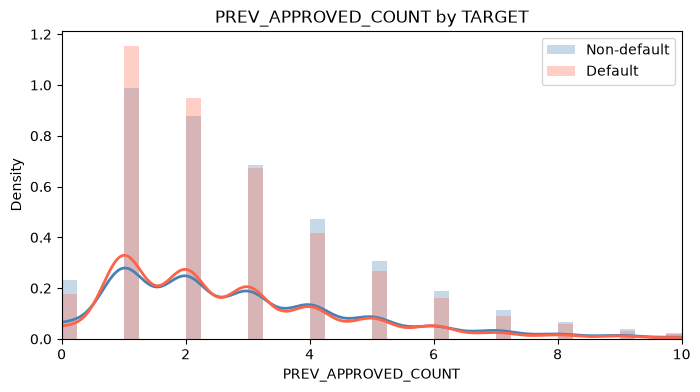

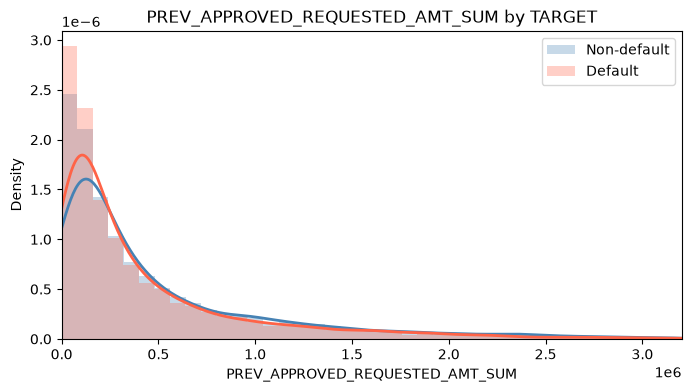

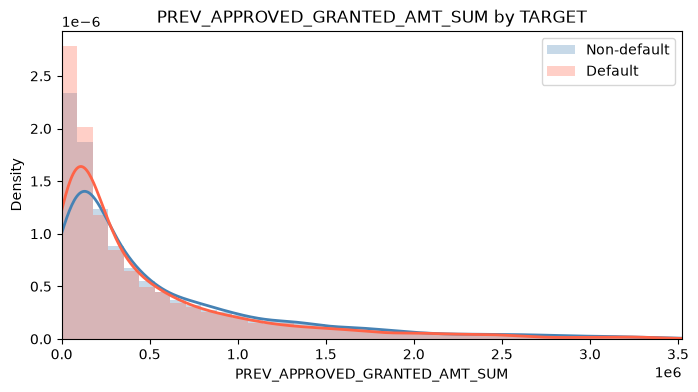

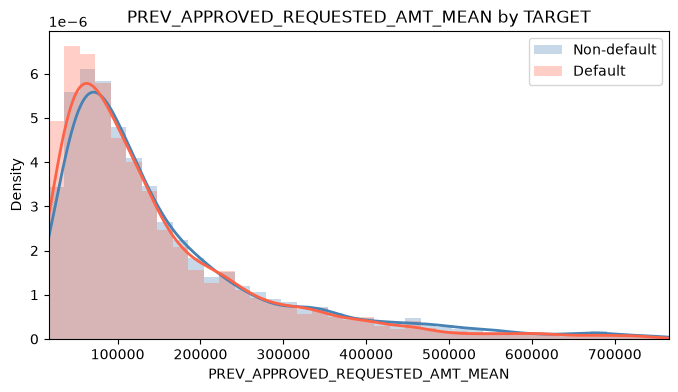

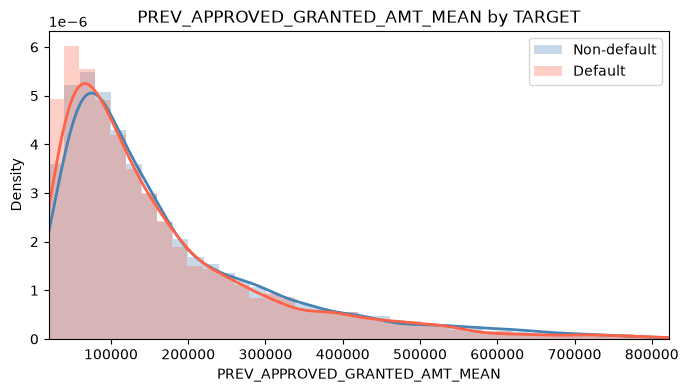

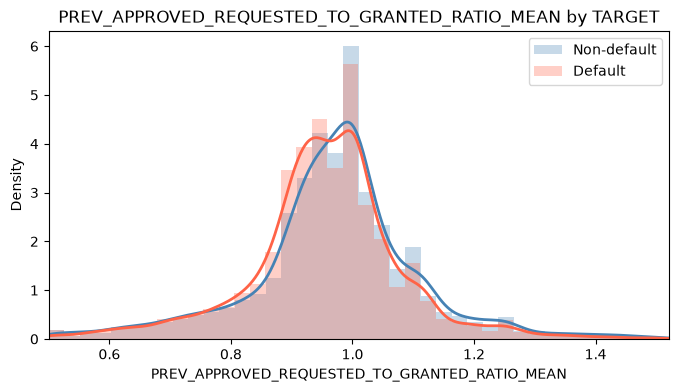

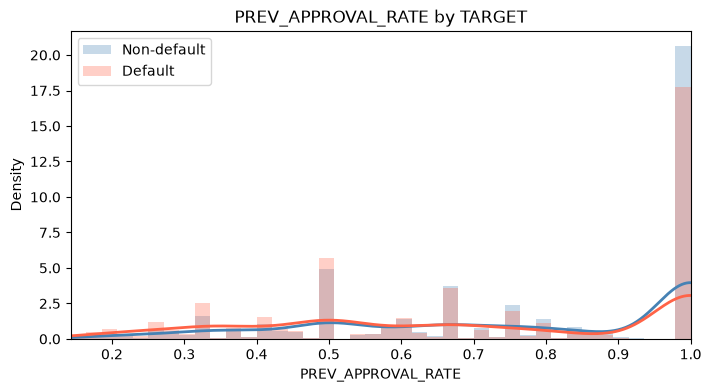

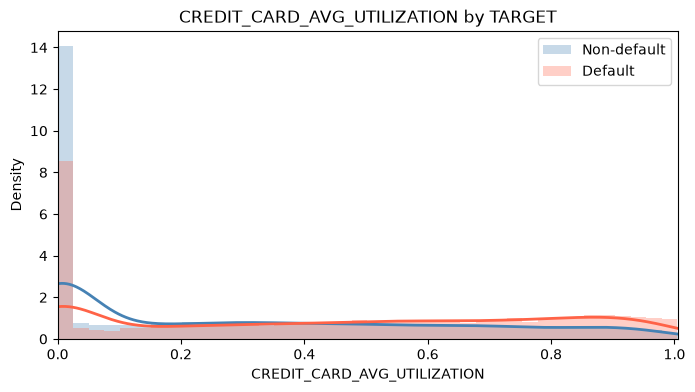

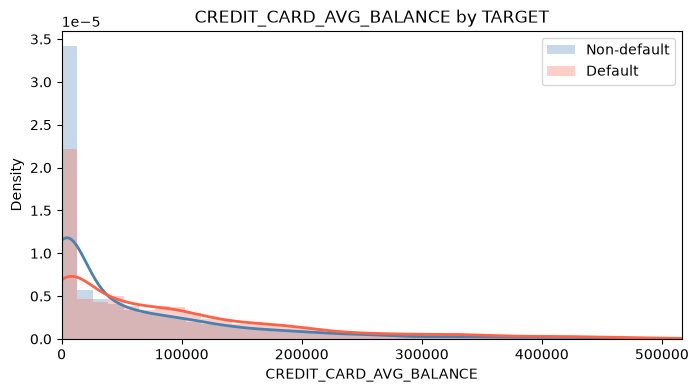

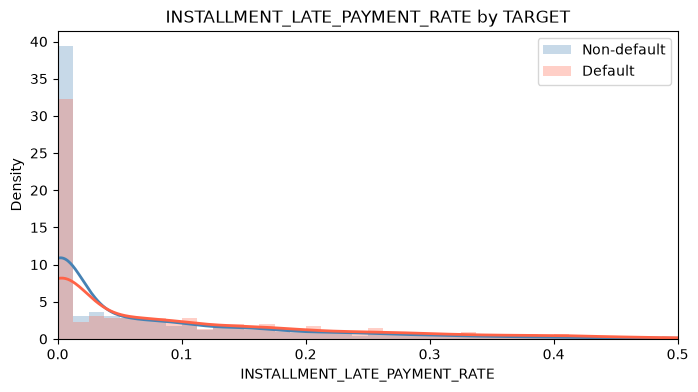

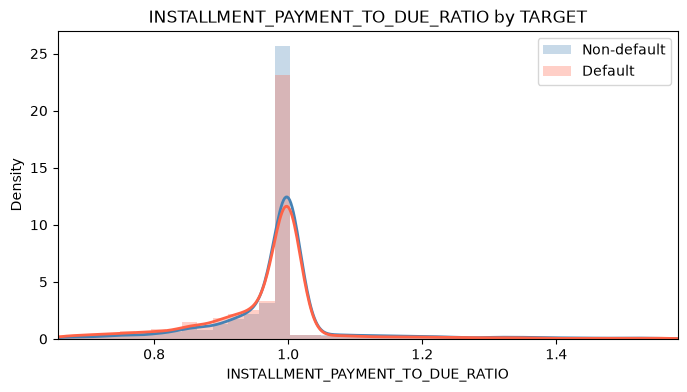

In [16]:
plot_features = numerical_features

for col in plot_features:
    lower, upper = eda_df[col].quantile([0.01, 0.99])
    if lower == upper:
        continue

    fig, ax = plt.subplots(figsize=(8, 4))

    for target, color, label in [
        (0, "steelblue", "Non-default"),
        (1, "tomato", "Default"),
    ]:
        values = eda_df.loc[eda_df[TARGET_COL] == target, col].dropna()
        values = values[values.between(lower, upper)]

        ax.hist(
            values, bins=40, density=True, alpha=0.30,
            color=color, label=label,
        )

        kde_sample = values.sample(
            n=min(len(values), 5_000), random_state=42
        )
        if kde_sample.nunique() > 1:
            kde_sample.plot.kde(
                ax=ax, color=color, linewidth=2, label="_nolegend_"
            )

    ax.set(xlabel=col, ylabel="Density", title=f"{col} by TARGET")
    ax.set_xlim(lower, upper)
    ax.legend()
    plt.show()

## Categorical Features

In [20]:
for col in categorical_features:
    levels = eda_df[col].astype("string").fillna("Missing")

    summary = (
        eda_df.groupby(levels)[TARGET_COL]
        .agg(["size", "sum", "mean"])
        .rename(columns={
            "size": "applications",
            "sum": "defaults",
            "mean": "default_rate",
        })
        .sort_values("applications", ascending=False)
    )
    summary["share_pct"] = (summary["applications"] / len(eda_df) * 100).round(2)
    summary["default_rate_pct"] = (summary["default_rate"] * 100).round(2)

    print(f"\n{col}")
    display(summary)


NAME_CONTRACT_TYPE


,applications,defaults,default_rate,share_pct,default_rate_pct
NAME_CONTRACT_TYPE,,,,,
Cash loans,222560,18572,0.083447,90.47,8.34
Revolving loans,23448,1288,0.054930,9.53,5.49



CODE_GENDER


,applications,defaults,default_rate,share_pct,default_rate_pct
CODE_GENDER,,,,,
F,161887,11334,0.070012,65.81,7.00
M,84119,8526,0.101356,34.19,10.14
Missing,2,0,0.000000,0.00,0.00



NAME_TYPE_SUITE


,applications,defaults,default_rate,share_pct,default_rate_pct
NAME_TYPE_SUITE,,,,,
Unaccompanied,198808,16286,0.081918,80.81,8.19
Family,32080,2390,0.074501,13.04,7.45
"Spouse, partner",9068,714,0.078738,3.69,7.87
Children,2673,194,0.072578,1.09,7.26
Other_B,1432,139,0.097067,0.58,9.71
Missing,1029,57,0.055394,0.42,5.54
Other_A,697,61,0.087518,0.28,8.75
Group of people,221,19,0.085973,0.09,8.60


... (46 outputs left out)


LIVE_CITY_NOT_WORK_CITY


,applications,defaults,default_rate,share_pct,default_rate_pct
LIVE_CITY_NOT_WORK_CITY,,,,,
0,201638,15419,0.076469,81.96,7.65
1,44370,4441,0.100090,18.04,10.01



EMERGENCYSTATE_MODE


,applications,defaults,default_rate,share_pct,default_rate_pct
EMERGENCYSTATE_MODE,,,,,
0,127570,8899,0.069758,51.86,6.98
Missing,116581,10786,0.092519,47.39,9.25
1,1857,175,0.094238,0.75,9.42


### Correlation Analysis

In [21]:
import numpy as np
import matplotlib.pyplot as plt

numeric_cols = list(dict.fromkeys(
    numerical_features + ["AGE_YEARS", "EMPLOYMENT_YEARS"]
))
numeric_cols = [col for col in numeric_cols if col in eda_df.columns]

corr = eda_df[numeric_cols].corr(method="pearson", min_periods=1000)
print(f"Correlation matrix: {corr.shape[0]} numeric features")

Correlation matrix: 90 numeric features


In [29]:
upper_triangle = np.triu(np.ones(corr.shape, dtype=bool), k=1)

pairs = (
    corr.where(upper_triangle)
    .stack()
    .rename("pearson_r")
    .reset_index()
)
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()

top_pairs = pairs.sort_values("abs_r", ascending=False).head(30).copy()
top_pairs["pairwise_rows"] = [
    (eda_df[a].notna() & eda_df[b].notna()).sum()
    for a, b in zip(top_pairs["feature_1"], top_pairs["feature_2"])
]

display(top_pairs.round(3))

,feature_1,feature_2,pearson_r,abs_r,pairwise_rows
719,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.000,1.000,201865
628,DAYS_BIRTH,AGE_YEARS,-1.000,1.000,246008
5553,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.999,0.999,245197
1939,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.998,0.998,82465
2394,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.997,0.997,79087
2303,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.997,0.997,123711
2212,ENTRANCES_AVG,ENTRANCES_MEDI,0.997,0.997,122233
2121,ELEVATORS_AVG,ELEVATORS_MEDI,0.996,0.996,114991
2030,COMMONAREA_AVG,COMMONAREA_MEDI,0.996,0.996,74197
2667,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.995,0.995,122546


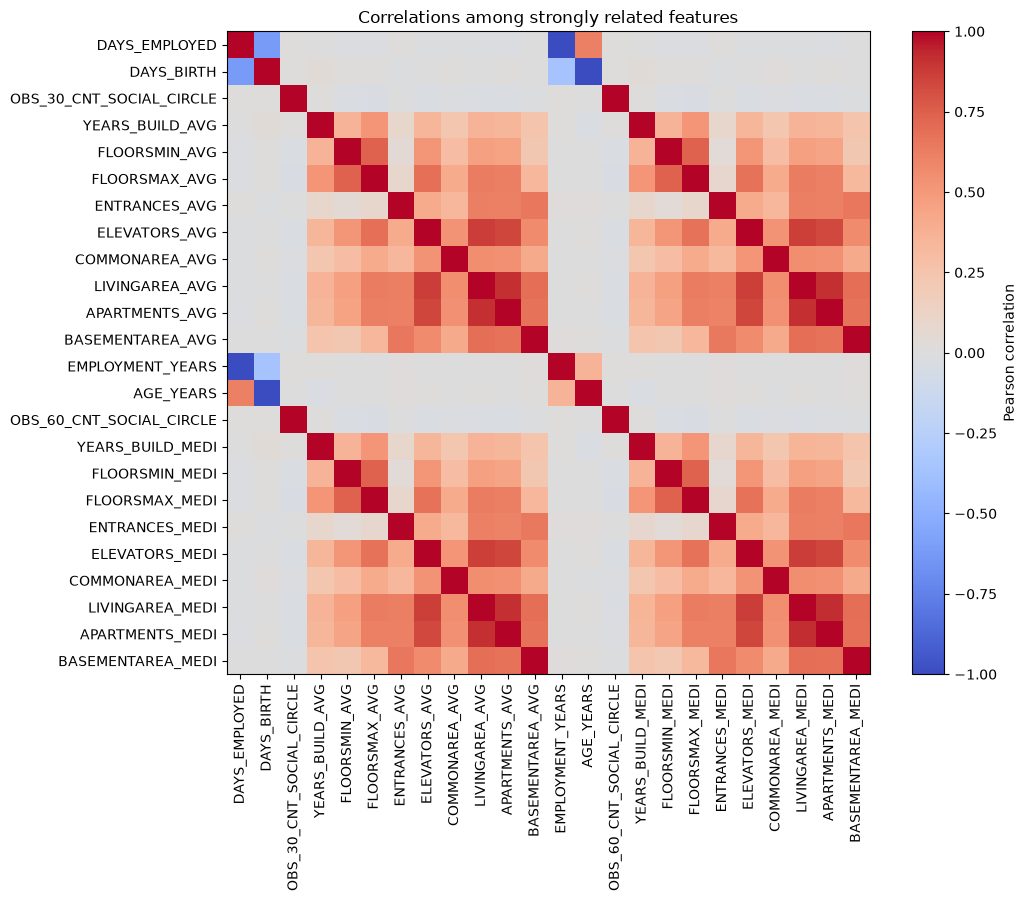

In [23]:
heatmap_cols = list(dict.fromkeys(
    top_pairs["feature_1"].head(12).tolist()
    + top_pairs["feature_2"].head(12).tolist()
))

heatmap = corr.loc[heatmap_cols, heatmap_cols]

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(heatmap, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(heatmap_cols)), labels=heatmap_cols, rotation=90)
ax.set_yticks(range(len(heatmap_cols)), labels=heatmap_cols)
ax.set_title("Correlations among strongly related features")
fig.colorbar(image, ax=ax, label="Pearson correlation")

plt.tight_layout()
plt.show()

In [25]:
numerical_features

['CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'HOUR_APPR_PROCESS_START',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_AVG',
 'YEARS_BUILD_AVG',
 'COMMONAREA_AVG',
 'ELEVATORS_AVG',
 'ENTRANCES_AVG',
 'FLOORSMAX_AVG',
 'FLOORSMIN_AVG',
 'LANDAREA_AVG',
 'LIVINGAPARTMENTS_AVG',
 'LIVINGAREA_AVG',
 'NONLIVINGAPARTMENTS_AVG',
 'NONLIVINGAREA_AVG',
 'APARTMENTS_MODE',
 'BASEMENTAREA_MODE',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BUILD_MODE',
 'COMMONAREA_MODE',
 'ELEVATORS_MODE',
 'ENTRANCES_MODE',
 'FLOORSMAX_MODE',
 'FLOORSMIN_MODE',
 'LANDAREA_MODE',
 'LIVINGAPARTMENTS_MODE',
 'LIVINGAREA_MODE',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAREA_MODE',
 'APARTMENTS_MEDI',
 'BASEMENTA